# Audits des sources — Compagnon Immobilier

**Projet :** Compagnon Immobilier · 

Ce notebook rassemble les audits de toutes les sources de données de l'équipe : une partie par source, dans l'ordre de la préparation. Chaque audit décrit la source telle qu'elle est livrée (origine, structure, variables, qualité) et justifie les choix faits ensuite dans `01_preparation`.

1. DVF+
2. Bassins de vie et table de passage des communes
3. Filosofi
4. Ménages (recensement 2022)
5. Parc de logement (recensement 2022)
6. Délinquance enregistrée
7. LOVAC
8. Équipements et sources complémentaires
9. Taux des crédits immobiliers
10. Annonces de vente (Haut-Rhin)
11. Annonces de location (Haut-Rhin)
12. Emploi salarié privé (Urssaf)

### Avant de lancer

- **Sources brutes** (`00_telechargement`) : `bassins_vie`, `passage_geo`, `menages`, `logement`, `delinquance`, `lovac`, `taux`. Pour DVF+, l'échantillon d'audit se construit à partir de DVF+ brut (`dvf`), sauf s'il est déjà présent.
- **Fichiers préparés** (`01_preparation`) : l'audit de Filosofi porte sur la base assemblée par le bloc 5 ; deux contrôles utilisent la population DVF+ filtrée (bloc 2) et la table de liaison (bloc 1).
- **Emploi** : le fichier `etablissements_effectifs_commune.parquet` (Urssaf) doit être dans `data/raw/`.
- **Annonces** : les fichiers `ech_annonces_ventes_68.csv` et `ech_annonces_locations_68.csv` doivent être dans `data/raw/`.



In [13]:
import sys
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

# config.py se trouve à la racine du projet, dossier parent de ce notebook
sys.path.insert(0, str(Path.cwd().parent))
#from config import DATA_RAW, DATA_OUT

pd.set_option("display.max_columns", None)

# Emploi salarié privé (Urssaf)

**Contributeurs :** Gabrielle RICHERT · **Date :** 04/11/2026

Source : `etablissements_effectifs_commune.parquet`, « Nombre d'établissements employeurs et effectifs salariés du secteur privé, par commune x APE (au 31/12 depuis 2006) », Urssaf, diffusé sur open.urssaf.fr et data.gouv.fr.

**Pourquoi cette source :** l'hypothèse H3c (tour 1 de la modélisation) teste si l'évolution de l'emploi en N-1 améliore la prévision du prix N. Il faut pour cela une valeur d'emploi **par territoire et par année**, ce que n'offrent ni le recensement (une seule photo, 2022) ni Filosofi. Le feature engineering (section « Emploi salarié privé ») en fait une table sous-bassin × année ; ce notebook se limite à l'audit de la source brute.

### Chargement

In [4]:
#chemin_emploi = DATA_RAW / "etablissements_effectifs_commune.parquet"
chemin_emploi=r"C:\Users\gabi9\Documents\etablissements_effectifs_commune.parquet"
emploi_brut = pd.read_parquet(chemin_emploi)

# Trois familles de colonnes : descriptives, nombre d'établissements par année, effectifs par année
col_etab = [c for c in emploi_brut.columns if c.startswith("Nombre d'établissements")]
col_eff = [c for c in emploi_brut.columns if c.startswith("Effectifs salariés")]
col_desc = [c for c in emploi_brut.columns if c not in col_etab + col_eff]
annees = sorted(int(c[-4:]) for c in col_eff)

print("Dimensions :", emploi_brut.shape)
print(len(col_desc), "colonnes descriptives |", len(col_etab), "colonnes d'établissements |",
      len(col_eff), "colonnes d'effectifs | années", annees[0], "à", annees[-1])
print(col_desc)

Dimensions : (1227408, 59)
19 colonnes descriptives | 20 colonnes d'établissements | 20 colonnes d'effectifs | années 2006 à 2025
['Région', 'Ancienne région', 'Département', "Zone d'emploi", 'EPCI', 'Nom commune', 'Commune', "Grand secteur d'activité", 'Secteur NA17', 'Secteur NA38', 'Secteur NA88', 'APE', 'Code région', 'Code ancienne région', 'Code département', "Code zone d'emploi", 'Code EPCI', 'Code commune', 'Code APE']


### 1. Situer la source et ouvrir les données

| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine | Urssaf (ex-Acoss), à partir des déclarations sociales des employeurs (DSN). | Page du jeu sur data.gouv.fr ; méthodologie sur open.urssaf.fr |
| Finalité initiale | Suivre l'emploi salarié et les établissements employeurs du secteur privé. Rien n'a été produit pour estimer des prix. | Aucun prix : pas de cible |
| Mode de collecte | Administratif et exhaustif : chaque employeur du régime général déclare ses salariés. Pas un sondage. | Effectif mesuré **en fin d'année** (contrats en cours au 31/12) |
| Extraction / mise à jour | Mise à jour annuelle, environ 150 jours après la fin de l'année : le 31/12/N est publié vers la fin mai de N+1. | Le fichier contient le 31/12/2025, donc publié en 2026 |
| Documentation / licence | Méthodologie de l'Urssaf ; licence ODbL. | Depuis la publication de juin 2023, les **apprentis** sont inclus dans les effectifs (ils étaient exclus avant) |
| Population / objets annoncés | Établissements employeurs du **secteur privé, régime général** et leurs salariés. | Ni la fonction publique, ni l'agriculture (régime agricole, MSA) |
| Période / territoire | 31/12/2006 à 31/12/2025 ; France métropolitaine et DOM, par commune et par activité (APE). | Mayotte absente (voir section 4) |

**Constat :** source administrative exhaustive sur l'emploi salarié privé, par commune, par activité et par année, sur 20 ans. Elle ne contient aucun prix.

**Impact projet :** c'est une variable explicative **annuelle** : elle respecte la règle « information connue en N-1 » et couvre à la fois le tour 1 (prix 2020-2025, emploi 2018-2024) et la période longue du tour 2 (prix dès 2017).

**Action envisagée :** passer du format commune × activité au format sous-bassin × année (feature engineering), en traitant le calendrier de publication et le secret statistique.

**Incertitudes / limites :** secteur privé seulement ; l'effectif du 31/12/N-1 n'est publié qu'au printemps de l'année N (décalage à discuter, voir synthèse) ; changement de champ (apprentis) à vérifier en section 5.3.

### 2. Comprendre la structure et une ligne

In [5]:
# ── 1. Dimensions, types ─────────────────────────────────────────────────────
emploi_brut.info(verbose=False)

# ── 2. Une ligne en entier, transposée pour tout voir ────────────────────────
display(emploi_brut.sample(1, random_state=0).T)

# ── 3. Doublons exacts et doublons sur la clé commune x activité ─────────────
print("Doublons exacts :", emploi_brut.duplicated().sum())
print("Doublons commune x APE :", emploi_brut.duplicated(["Code commune", "Code APE"]).sum())
print("Codes commune :", emploi_brut["Code commune"].nunique(),
      "| communes réelles (zéro initial remis) :", emploi_brut["Code commune"].astype(str).str.zfill(5).nunique(),
      "| codes APE :", emploi_brut["Code APE"].nunique())
print("Doublons commune x APE après correction du code :",
      emploi_brut.assign(c=emploi_brut["Code commune"].astype(str).str.zfill(5)).duplicated(["c", "Code APE"]).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1227408 entries, 0 to 1227407
Columns: 59 entries, Région to Effectifs salariés 2025
dtypes: float64(40), int64(3), string(16)
memory usage: 954.5 MB


,305228
Région,Île-de-France
Ancienne région,Île-de-France
Département,Seine-Saint-Denis
Zone d'emploi,Paris
EPCI,Métropole du Grand Paris
Nom commune,Le Raincy
Commune,93062 Le Raincy
Grand secteur d'activité,GS2 Construction
Secteur NA17,FZ Construction
Secteur NA38,FZ Construction


Doublons exacts : 0
Doublons commune x APE : 0
Codes commune : 34270 | communes réelles (zéro initial remis) : 33696 | codes APE : 689
Doublons commune x APE après correction du code : 0


| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 1 227 408 lignes × 59 colonnes : 19 descriptives, 20 colonnes « Nombre d'établissements AAAA » et 20 colonnes « Effectifs salariés AAAA » (2006 à 2025). |
| Contenu général, en une phrase | Pour chaque commune (33 696) et chaque activité (APE) : le nombre d'établissements employeurs et le nombre de salariés au 31/12 de chaque année de 2006 à 2025. |
| Unité d'observation | Une **cellule commune × activité** (code APE, 689 activités). Paris, Lyon et Marseille par arrondissement. |
| Identifiants / clés possibles | `Code commune` (zéro initial remis) + `Code APE` : unique (0 doublon, avant comme après correction du code). |
| Une ou plusieurs lignes par objet ? Pourquoi ? | Plusieurs lignes par commune (une par activité présente au moins une année) ; **les années sont en colonnes** (format large). |
| Doublons exacts : nombre / proportion | 0 (0 %). |
| Répétitions métier : règle examinée / résultat | Commune × APE répétée : aucune. |

**Constat :** une ligne par commune × activité, clé unique, aucun doublon ; 20 millésimes stockés en colonnes.

**Impact projet :** pour le modèle, seule compte la somme des salariés par territoire et par année : le détail par activité sert seulement à calculer une évolution fiable (feature engineering).

**Action envisagée :** passer au format long (une ligne par cellule et par année), puis additionner par sous-bassin.

**Incertitudes / limites :** une même cellule apparaît sur toutes les années, y compris celles où l'activité n'existait pas dans la commune (voir 5.1).

### 3. Comprendre les variables

In [6]:
from pandas.api.types import is_numeric_dtype

# Une ligne de résumé par colonne : les descriptives, puis une année de chiffres pour l'exemple
resume = []
for col in col_desc + ["Nombre d'établissements 2024", "Effectifs salariés 2024"]:
    if is_numeric_dtype(emploi_brut[col]):
        valeurs = "min = " + str(emploi_brut[col].min()) + ", max = " + str(emploi_brut[col].max())
    elif emploi_brut[col].nunique() <= 8:
        valeurs = str(list(emploi_brut[col].dropna().unique()))
    else:
        valeurs = str(emploi_brut[col].nunique()) + " modalités"
    resume.append({"variable": col, "type": str(emploi_brut[col].dtype), "valeurs": valeurs,
                   "% NaN": round(emploi_brut[col].isna().mean() * 100, 1)})
display(pd.DataFrame(resume).set_index("variable"))

,type,valeurs,% NaN
variable,,,
Région,string,17 modalités,0.0
Ancienne région,string,26 modalités,0.0
Département,string,100 modalités,0.0
Zone d'emploi,string,304 modalités,0.0
EPCI,string,1247 modalités,0.0
Nom commune,string,31586 modalités,0.0
Commune,string,33696 modalités,0.0
Grand secteur d'activité,string,"['GS3 Commerce', 'GS4 Hôtellerie-restauration'...",0.0
Secteur NA17,string,17 modalités,0.0


| Variable | Signification | Nature statistique | Unité / modalités | Type de stockage et cohérence |
|---|---|---|---|---|
| `Code commune` | Code Insee de la commune (arrondissement pour Paris, Lyon, Marseille) | Qualitative nominale (identifiant) | 34 270 codes pour 33 696 communes | Texte, mais **zéro initial perdu** pour une partie des lignes des départements 01 à 09 (`8081` au lieu de `08081`) : 574 communes apparaissent sous les deux écritures, selon l'activité → à corriger |
| `Code APE` / `APE` | Activité principale de l'établissement (NAF rév. 2, 732 postes) | Qualitative nominale | 689 codes présents | Texte : cohérent |
| `Grand secteur d'activité`, `Secteur NA17/NA38/NA88` | Regroupements de l'APE | Qualitative nominale | 7 grands secteurs + 1 « non classé » | Texte : cohérent |
| `Code département`, `Code région`, `Code zone d'emploi`, `Code EPCI` | Territoires d'appartenance de la commune | Qualitative nominale | 100 départements ; 305 zones d'emploi | Codes région et zone d'emploi lus comme nombres ; département sans zéro initial (`8`) |
| `Nombre d'établissements AAAA` | Établissements employeurs actifs au 31/12 | Quantitative discrète | Établissements | Nombre : cohérent |
| `Effectifs salariés AAAA` | Salariés au 31/12 (contrats en cours), apprentis compris | Quantitative discrète | Salariés | Nombre : cohérent (entiers, aucun négatif) |

**Variables ambiguës / documentation manquante :** l'effectif compte des **postes** au lieu de travail, pas des habitants : un sous-bassin où se trouve un grand employeur a beaucoup d'emplois même si ses salariés habitent ailleurs. Les intérimaires sont comptés dans l'agence d'intérim, pas là où ils travaillent.

**Utilité provisoire pour le projet :** niveau d'emploi rapporté au parc de logements, et évolution sur un an, par sous-bassin.

**Si prédiction : disponibilité au moment de prédire / risques de fuite :** l'effectif au 31/12/N-1 est publié fin mai de N. Pour un prix de l'année N, il faut au plus l'effectif du 31/12/N-1 (convention de l'équipe), et jamais celui du 31/12/N (fuite). Version prudente : 31/12/N-2.

**Constat :** des chiffres propres (entiers, aucun négatif) mais un code commune abîmé pour les départements 01 à 09.

**Impact projet :** sans correction, 6 % des lignes ne trouveraient pas leur sous-bassin, et 574 communes seraient coupées en deux.

**Action envisagée :** remettre le zéro initial (`zfill(5)`) avant toute jointure ; ne garder que le code commune, le code APE et les chiffres.

**Incertitudes / limites :** lieu de travail ≠ lieu de résidence ; intérim compté à l'agence.

### 4. Vérifier le périmètre réel

In [7]:
emploi = emploi_brut.copy()
emploi["code_commune"] = emploi["Code commune"].astype(str).str.zfill(5)
print("Longueur des codes avant correction :", emploi_brut["Code commune"].astype(str).str.len().value_counts().to_dict())

# ── Géographie ───────────────────────────────────────────────────────────────
departements = emploi["code_commune"].str[:2].where(~emploi["code_commune"].str.startswith("97"),
                                                     emploi["code_commune"].str[:3])
print("Départements :", departements.nunique(), "| outre-mer :", sorted(departements[departements.str.startswith("97")].unique()))
print("Corse (2A, 2B) :", departements.isin(["2A", "2B"]).sum(), "lignes")
print("Paris, Lyon, Marseille en commune entière :",
      emploi.loc[emploi["code_commune"].isin(["75056", "69123", "13055"]), ["code_commune", "APE"]].values.tolist())
print("Arrondissements :", emploi.loc[emploi["code_commune"].str.match(r"^(751\d\d|6938\d|132\d\d)$"), "code_commune"].nunique())

# ── Communes avec au moins un établissement, par année ───────────────────────
actives = pd.Series({a: emploi.loc[emploi[f"Nombre d'établissements {a}"] > 0, "code_commune"].nunique() for a in annees})
print("\nCommunes avec au moins un établissement :", actives.loc[[2006, 2015, 2020, 2024, 2025]].to_dict())

# ── Temps : total national par année ─────────────────────────────────────────
national = pd.DataFrame({"salariés (millions)": [emploi[f"Effectifs salariés {a}"].sum() / 1e6 for a in annees],
                         "établissements (milliers)": [emploi[f"Nombre d'établissements {a}"].sum() / 1e3 for a in annees]},
                        index=annees)
national["évolution des salariés (%)"] = national["salariés (millions)"].pct_change() * 100
display(national.round(2))

Longueur des codes avant correction : {5: 1153594, 4: 73814}
Départements : 100 | outre-mer : ['971', '972', '973', '974']
Corse (2A, 2B) : 9393 lignes
Paris, Lyon, Marseille en commune entière : [['13055', '4772A Commerce de détail de la chaussure'], ['75056', '9499Z Autres organisations fonctionnant par adhésion volontaire']]
Arrondissements : 45

Communes avec au moins un établissement : {2006: 30561, 2015: 30380, 2020: 30292, 2024: 30598, 2025: 30611}


,salariés (millions),établissements (milliers),évolution des salariés (%)
2006,17.78,1726.24,NaN
2007,18.08,1754.00,1.70
2008,17.95,1774.87,-0.70
2009,17.55,1775.28,-2.24
2010,17.68,1786.80,0.75
2011,17.82,1793.75,0.77
2012,17.73,1791.56,-0.48
2013,17.66,1789.91,-0.39
2014,17.62,1787.42,-0.24
2015,17.70,1789.19,0.45


| Dimension | Couverture observée | Effectifs / preuve | Écart / limite |
|---|---|---|---|
| Population / objets | Salariés du secteur privé, régime général | 20,0 millions de salariés et 1,90 million d'établissements au 31/12/2024 | Ni fonction publique ni agriculture : l'emploi total d'un territoire est sous-estimé, surtout dans les villes préfectures (public) et le rural (agriculture) |
| Temps | 20 millésimes, 31/12/2006 à 31/12/2025 | De 17,8 millions (2006) à 20,0 millions (2024) | Toutes les années utiles au projet sont là : prix 2017 à 2025 → emploi 2015 à 2024 |
| Géographie | 100 départements : 96 de métropole (dont 2A et 2B) et 4 DOM (971 à 974) | 33 696 communes dans le fichier ; 30 598 avec au moins un établissement en 2024 | **Mayotte absente** (déjà hors de DVF+) ; les communes sans aucun employeur privé n'apparaissent pas (0 salarié) |
| Paris, Lyon, Marseille | Par arrondissement | 45 arrondissements ; 2 lignes isolées au code de la ville (75056, 13055) | Même codage que DVF+ et LOVAC : correction de la table de liaison (RENDU 1) |

**Constat :** la couverture nationale est complète hors Mayotte, sur 20 ans, mais limitée au secteur privé ; une commune absente du fichier est une commune sans employeur privé, pas une donnée perdue.

**Impact projet :** toutes les lignes de la table de modélisation peuvent recevoir une valeur d'emploi (0 si aucun employeur).

**Action envisagée :** à la jointure, compter les communes de la table de liaison absentes du fichier et vérifier qu'il s'agit bien de petites communes ; compter les effectifs non rattachés à un sous-bassin.

**Incertitudes / limites :** la géographie communale du fichier (millésime du code officiel géographique) n'est pas indiquée ; les fusions de communes sont rattrapées par `CODGEO_INI` de la table de liaison.

### 5. Repérer et investiguer les problèmes de qualité

#### 5.1 Valeurs manquantes
Environ 42 % des cases d'effectifs sont vides chaque année. Deux situations très différentes peuvent se cacher derrière une case vide : la cellule n'avait **aucun établissement** cette année-là (l'activité n'existait pas, ou plus, dans la commune), ou elle en avait mais l'effectif est **caché par le secret statistique**. On les sépare avec le nombre d'établissements de la même année.

In [8]:
lignes = []
for a in annees:
    eff, etab = emploi[f"Effectifs salariés {a}"], emploi[f"Nombre d'établissements {a}"]
    lignes.append({"année": a,
                   "cases vides (%)": eff.isna().mean() * 100,
                   "dont sans établissement": (eff.isna() & ~(etab > 0)).sum(),
                   "dont secret (établissement mais effectif vide)": (eff.isna() & (etab > 0)).sum(),
                   "établissements sous secret": etab[eff.isna() & (etab > 0)].sum(),
                   "cases vides identiques effectifs et établissements (%)": (eff.isna() == etab.isna()).mean() * 100})
manquants = pd.DataFrame(lignes).set_index("année")
display(manquants.round(2))

secret_2024 = emploi[emploi["Effectifs salariés 2024"].isna() & (emploi["Nombre d'établissements 2024"] > 0)]
print("Secret 2024 : nombre d'établissements par cellule :", secret_2024["Nombre d'établissements 2024"].value_counts().to_dict())
display(secret_2024[["code_commune", "Nom commune", "APE"]].head(5))

,cases vides (%),dont sans établissement,dont secret (établissement mais effectif vide),établissements sous secret,cases vides identiques effectifs et établissements (%)
année,,,,,
2006,45.82,562391,3,3.0,100.00
2007,45.06,553059,1,1.0,100.00
2008,44.47,545770,4,4.0,100.00
2009,44.44,545497,1,1.0,100.00
2010,44.29,543624,3,3.0,100.00
2011,44.22,542799,0,0.0,100.00
2012,44.26,543298,0,0.0,100.00
2013,44.37,544638,0,0.0,100.00
2014,44.46,545668,0,0.0,100.00


Secret 2024 : nombre d'établissements par cellule : {1.0: 69}


,code_commune,Nom commune,APE
9774,06026,Cabris,8559A Formation continue d'adultes
52584,15038,Champs-sur-Tarentaine-Marchal,1071C Boulangerie et boulangerie-pâtisserie
74927,26061,Bren,5630Z Débits de boissons
89089,29260,Saint-Renan,9104Z Gestion des jardins botaniques et zoolog...
90223,2A209,Peri,4333Z Travaux de revêtement des sols et des murs


| Variable | Nombre / proportion | Codes d'absence possibles | Sens / structure observée |
|---|---|---|---|
| `Effectifs salariés AAAA` | 42 % à 46 % de cases vides selon l'année | Case vide | **Presque toujours une absence d'activité** : la case des établissements est vide elle aussi. La cellule existe parce que l'activité a été présente une autre année |
| `Effectifs salariés AAAA` (secret) | 0 à 5 cellules par an jusqu'en 2017, puis 44 à 149 (au plus 0,01 %) | Case vide alors qu'il y a un établissement | **Secret statistique** : toujours une cellule à un seul établissement |
| `Nombre d'établissements AAAA` | Mêmes cases vides que les effectifs | Case vide | Absence d'activité |

**Hypothèse de mécanisme :** l'absence n'est pas une donnée manquante mais un **zéro** : aucun établissement, donc aucun salarié. Le secret, lui, est non aléatoire (MNAR par construction : il cache les cellules à un seul établissement), mais il est marginal.

**Éléments à l'appui et limites :** les cases vides des effectifs et des établissements coïncident dans 99,99 % à 100 % des cas selon l'année ; en 2024, les 69 cellules sous secret ont toutes exactement 1 établissement.

**Constat :** les cases vides sont des zéros, pas des valeurs manquantes ; le vrai secret est négligeable (au plus 149 cellules par an sur 1,2 million).

**Impact projet :** les traiter comme des valeurs manquantes serait une erreur grave. Pour calculer une évolution « à champ constant », on retirerait toutes les cellules absentes une des deux années, c'est-à-dire **toutes les ouvertures et fermetures d'établissements**, qui sont justement une part réelle de l'évolution de l'emploi.

**Action envisagée :** case vide sans établissement → 0 salarié ; case vide avec établissement → secret (valeur manquante), exclue de l'évolution les deux années ; part des cellules sous secret gardée comme variable de contrôle qualité (`part_emploi_secret`).

**Incertitudes / limites :** l'effectif caché est petit (un seul établissement), l'erreur sur un total de sous-bassin est négligeable.

#### 5.2 Formats, modalités et incohérences

In [9]:
controles = []
for a in (2019, 2023, 2024):
    eff, etab = emploi[f"Effectifs salariés {a}"], emploi[f"Nombre d'établissements {a}"]
    controles.append({"année": a,
                      "salariés > 0 sans établissement": ((eff > 0) & ~(etab > 0)).sum(),
                      "établissement avec 0 salarié": ((etab > 0) & (eff == 0)).sum(),
                      "valeurs négatives": int((eff < 0).sum() + (etab < 0).sum()),
                      "effectifs non entiers": int((eff.dropna() % 1 != 0).sum())})
display(pd.DataFrame(controles).set_index("année"))

print("Lignes « non classé » :", emploi.loc[emploi["Grand secteur d'activité"].str.startswith("nca"), ["code_commune", "APE"]].values.tolist())
print("Codes département à 1 caractère :", sorted(c for c in emploi_brut["Code département"].astype(str).unique() if len(c) == 1))

,salariés > 0 sans établissement,établissement avec 0 salarié,valeurs négatives,effectifs non entiers
année,,,,
2019,0,12627,0,0
2023,0,7252,0,0
2024,0,6536,0,0


Lignes « non classé » : [['66017', '0000Z Inconnu']]
Codes département à 1 caractère : ['1', '2', '3', '4', '5', '6', '7', '8', '9']


| Variable(s) | Règle / point contrôlé | Nombre de cas | Exemple / explication possible |
|---|---|---|---|
| `Code commune` | 5 caractères | 73 814 lignes à 4 caractères (6 %) ; 574 communes écrites des deux façons | Zéro initial perdu (départements 01 à 09) : `8081` pour `08081` ; aucun doublon commune × APE une fois corrigé |
| `Code département` | 2 ou 3 caractères | Départements 1 à 9 sans zéro | Même cause |
| Salariés et établissements | Des salariés sans établissement | 0 | Cohérent |
| Établissements et salariés | Un établissement avec 0 salarié | 6 536 cellules en 2024, 12 627 en 2019 | Normal selon l'Urssaf : salaires versés dans l'année mais plus de contrat au 31/12 |
| Effectifs | Entiers, positifs | 0 non entier, 0 négatif | Cohérent |
| `Grand secteur d'activité` | 7 grands secteurs | 1 ligne « nca » (APE 0000Z, Saint-Estève 66017), vide | Sans effet |

**Constat :** pas d'incohérence entre établissements et salariés ; le seul défaut de format est le zéro initial perdu des codes.

**Impact projet :** corriger le code avant la jointure suffit.

**Action envisagée :** `zfill(5)` sur le code commune ; ignorer les colonnes descriptives inutiles (régions, EPCI, secteurs).

**Incertitudes / limites :** aucune.

#### 5.3 Distributions et valeurs extrêmes
Trois questions : (1) la série nationale présente-t-elle une rupture, en particulier avec l'inclusion des apprentis ? (2) l'emploi est-il très concentré dans quelques communes ? (3) l'évolution d'une année sur l'autre est-elle fiable dans les petites communes ?

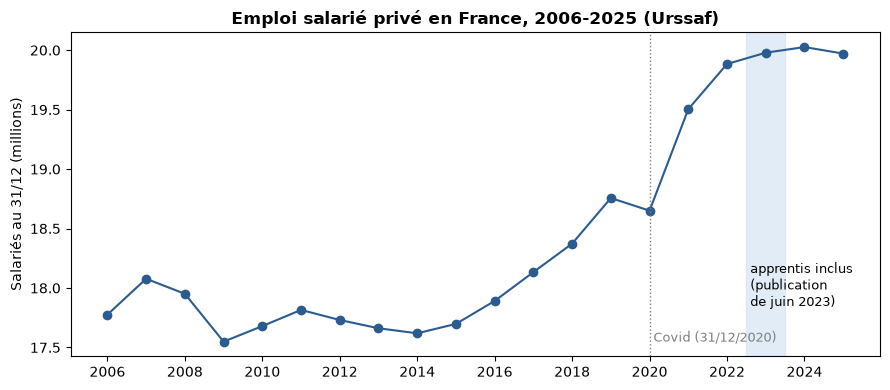

count     33696.0
mean        594.0
std        4346.0
min           0.0
10%           1.0
25%           4.0
50%          22.0
75%         138.0
90%         756.0
99%        9967.0
max      249806.0
Name: Effectifs salariés 2024, dtype: float64
1 % des communes regroupent 50.3% des salariés


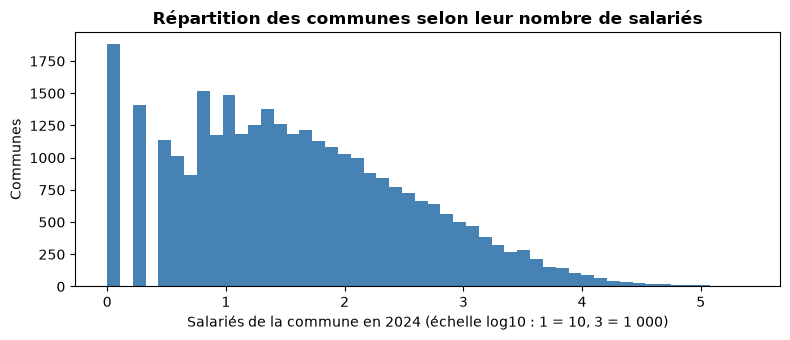

Grand secteur d'activité
GS1 Industrie                                 15.9
GS2 Construction                               8.0
GS3 Commerce                                  16.9
GS4 Hôtellerie-restauration                    6.5
GS5 Autres services marchands hors intérim    37.1
GS6 Intérim                                    2.6
GS7 Services non marchands                    13.1
nca _non classé ailleurs_                      0.0
Name: part des salariés 2024 (%), dtype: float64

,count,mean,std,min,5%,50%,95%,max
taille,,,,,,,,
1-10,9546.0,6.8,78.9,-100.0,-100.0,0.0,100.0,2633.3
11-50,8185.0,-0.3,21.3,-100.0,-30.8,0.0,30.8,300.0
51-200,5692.0,-0.2,12.2,-100.0,-15.4,0.0,15.1,291.4
201-1 000,4338.0,0.2,7.0,-61.0,-9.1,0.0,9.4,103.4
1 001-10 000,2436.0,0.3,4.6,-33.1,-5.7,0.1,6.9,52.9
> 10 000,335.0,0.1,2.4,-9.4,-4.0,0.2,3.9,9.7


In [10]:
# ── 1. Série nationale : rupture ? ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(national.index, national["salariés (millions)"], marker="o", color="#2b5c8f")
ax.axvline(2020, color="grey", ls=":", lw=1)
ax.text(2020.1, national["salariés (millions)"].min(), "Covid (31/12/2020)", color="grey", fontsize=9)
ax.axvspan(2022.5, 2023.5, color="#c6dbef", alpha=0.5)
ax.text(2022.6, national["salariés (millions)"].min() + 0.3, "apprentis inclus\n(publication\nde juin 2023)", fontsize=9)
ax.set_xticks(range(annees[0], annees[-1] + 1, 2))
ax.set_ylabel("Salariés au 31/12 (millions)")
ax.set_title("Emploi salarié privé en France, 2006-2025 (Urssaf)", fontweight="bold")
plt.tight_layout(); plt.show()

# ── 2. Concentration : salariés par commune en 2024 ──────────────────────────
par_commune = emploi.groupby("code_commune")["Effectifs salariés 2024"].sum()
print(par_commune.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(0))
top = par_commune.sort_values(ascending=False)
print(f"1 % des communes regroupent {top.head(len(top) // 100).sum() / top.sum():.1%} des salariés")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.log10(par_commune[par_commune > 0]), bins=50, color="#4682b4")
ax.set_xlabel("Salariés de la commune en 2024 (échelle log10 : 1 = 10, 3 = 1 000)")
ax.set_ylabel("Communes")
ax.set_title("Répartition des communes selon leur nombre de salariés", fontweight="bold")
plt.tight_layout(); plt.show()

# Part de chaque grand secteur (l'intérim est compté à l'agence, pas au lieu de mission)
secteurs = emploi.groupby("Grand secteur d'activité")["Effectifs salariés 2024"].sum()
display((secteurs / secteurs.sum() * 100).round(1).rename("part des salariés 2024 (%)"))

# ── 3. Évolution 2023 -> 2024 selon la taille de la commune ──────────────────
a = emploi.groupby("code_commune")[["Effectifs salariés 2023", "Effectifs salariés 2024"]].sum()
a = a[a["Effectifs salariés 2023"] > 0]
a["évolution (%)"] = (a["Effectifs salariés 2024"] / a["Effectifs salariés 2023"] - 1) * 100
a["taille"] = pd.cut(a["Effectifs salariés 2023"], [0, 10, 50, 200, 1000, 10_000, np.inf],
                     labels=["1-10", "11-50", "51-200", "201-1 000", "1 001-10 000", "> 10 000"])
display(a.groupby("taille", observed=True)["évolution (%)"].describe(percentiles=[0.05, 0.5, 0.95]).round(1))

**Constat :**
- **Pas de rupture visible autour de 2023** : +0,5 % au 31/12/2023, +0,2 % en 2024, dans la continuité des années précédentes. Le fichier, publié en 2026, semble avoir été recalculé apprentis compris sur toute la période (à confirmer dans la méthodologie de l'Urssaf). Les deux mouvements marquants sont réels : le Covid (−0,6 % au 31/12/2020) et le rebond de 2021 (+4,6 %), porté aussi par l'essor de l'apprentissage.
- **Très forte concentration** : la commune médiane compte 22 salariés privés (1 sur 10 en compte au plus 1), mais 1 % des communes regroupent la moitié des salariés. Le niveau d'emploi est donc très asymétrique, d'où son passage en log pour la régression (règle de l'audit : asymétrie > 1) et sa division par le parc de logements.
- **Évolutions très bruitées dans les petites communes** : entre 2023 et 2024, 90 % des communes de 1 à 10 salariés varient entre −100 % et +100 % ; une ouverture ou une fermeture suffit. L'écart se resserre avec la taille : entre −6 % et +7 % de 1 001 à 10 000 salariés, entre −4 % et +4 % au-delà.
- L'intérim pèse 2,6 % des salariés, compté au lieu de l'agence.

**Impact projet :** l'évolution n'a de sens qu'agrégée ; le sous-bassin (au moins 20 ventes, donc une certaine taille) lisse ce bruit. Le Covid touche l'emploi au 31/12/2020, utilisé pour les prix 2021 : à lire avec prudence.

**Action envisagée :** agréger au sous-bassin avant de calculer l'évolution ; rapporter le niveau au parc de logements ; garder l'année 2020 comme limite déclarée.

**Incertitudes / limites :** la série ne permet pas de séparer l'effet des apprentis du reste de l'emploi.

## Synthèse du premier niveau d'audit — Emploi salarié privé (Urssaf)

#### Constat

Le fichier de l'Urssaf est une source administrative exhaustive de l'emploi salarié **privé** : 1 227 408 cellules commune × activité, 20 millésimes au 31/12 (2006 à 2025), 33 696 communes de métropole et des DOM hors Mayotte, et 20,0 millions de salariés au 31/12/2024. Aucun doublon, des chiffres entiers et positifs, aucune incohérence entre établissements et salariés.

Trois points demandent un traitement :
- **les cases vides sont des zéros** : environ 42 % des cases sont vides parce que l'activité n'existait pas dans la commune cette année-là. Le vrai secret statistique ne touche qu'au plus 149 cellules par an, chacune à un seul établissement ;
- **le code commune a perdu son zéro initial** pour une partie des lignes des départements 01 à 09 (6 % des lignes ; 574 communes écrites des deux façons) ;
- **l'évolution est très bruitée dans les petites communes** : elle n'a de sens qu'agrégée au sous-bassin.

La série nationale ne montre pas de rupture liée à l'inclusion des apprentis ; le Covid (31/12/2020) et le rebond de 2021 sont des mouvements réels.

#### Conséquences pour le projet

- L'emploi est la première variable de la table qui **change chaque année dans chaque territoire** : c'est l'objet de l'hypothèse H3c.
- Toutes les années utiles sont disponibles, pour le tour 1 comme pour la période longue du tour 2.
- Limites à déclarer : secteur privé seulement (ni public ni agriculture) ; emplois comptés au lieu de travail, pas de résidence ; intérim compté à l'agence ; une même valeur pour appartements et maisons ; calendrier de publication (31/12/N-1 connu en mai de N).

#### Décisions pour la suite

- Code commune remis sur 5 caractères ; case vide sans établissement = 0 salarié ; case vide avec établissement = secret, exclue de l'évolution.
- Agrégation au sous-bassin par la table de liaison, puis trois variables : `emploi_par_logement`, `evol_emploi_n2_n1` (à champ constant) et `part_emploi_secret` (contrôle qualité, à ajouter à `HORS_MASQUE` dans `commun.py`).
- Calendrier : effectif du 31/12/N-1 pour les prix de N (convention de l'équipe), variante prudente au 31/12/N-2 testée dans H3c.
- L'emploi entre dans la table par le feature engineering, comme les autres sources : section « Emploi salarié privé (Urssaf) » de `feature_engineering.py` et `feature_engineering.ipynb`, export `fe_cible_emploi_sbv.parquet`.